# פרויקט 03 — VISION: עם מסכה או ללא מסכה

מחברת לימודית בעברית. רשת CNN קטנה מאפס, לפי שתי שכבות הקונבולוציה במחברת הכיתה.

**מיפוי קבוע:** `with_mask = 0`, `without_mask = 1`. פלט Sigmoid הוא ההסתברות למחלקה 1.

הנתונים: [המאגר שהמרצה קישר](https://www.kaggle.com/datasets/shiekhburhan/face-mask-dataset), גרסה 1. איננו משתמשים במחלקה `incorrect_mask`. תתי־התיקיות `simple` ו־`complex` אינן תוויות או פיצולי נתונים.

**הריצה המצורפת בוצעה ב־Google Colab עם T4 GPU:** 20 אפוקים, מודל מאפוק 16, דיוק מבחן 94.17% על 1,321 תמונות. גרסת המודל `20261017T175219Z`. פלטי האימון נשמרו מהריצה המקורית; לאחר ניתוק הסביבה שוחזר המודל מ־Drive ובוצעה תחזית תמונה ללא אימון חוזר. לכן מוני התאים אינם רצף אחד.

לאחר ביטול בחירת קובץ, הריצו שוב **רק את תא התחזית בסעיף 8**. לאחר איפוס הסביבה: תא הסביבה בסעיף 1, הגדרות העיבוד בסעיף 3, פונקציות העזר הראשונות בסעיף 4, ותא השחזור בסעיף 8. אין צורך ב־Run all. אימון חדש הוא פעולה נפרדת.

[מטלה](https://pythonai211225-rgb.github.io/advanced_ai/project03_cnn.pdf) · [הסבר הקורס](https://pythonai211225-rgb.github.io/advanced_ai/02_cnn/index.html) · [מחברת הכיתה](https://github.com/pythonai211225-rgb/11.10.2026/blob/main/cnn.ipynb)

**עדכון תאימות לאחר האימון:** מפענח התמונות הורחב מקומית לקבלת JPEG מסוג MPO ולבחירת התמונה הראשית בלבד. אותו תיקון נמצא בשרת. פלטי האימון המקוריים נשמרו; המחברת לא הורצה מחדש לאחר שינוי זה, והמשקלים ומדדי האימון לא השתנו. בדיקות מקומיות מאמתות את התיקון.


**אימות הגשה 21.10.2026:** תלויות ההתקנה עודכנו לאחר הריצה המקורית. אין להריץ שוב את האימון לצורך הדגמת האתר. פרטי ההרצה ההיסטורית והאימות העדכני מפורטים ב־README ובדוחות.


## 1. סביבת העבודה וחיבור ל־Google Drive
הריצה ההיסטורית המצורפת בוצעה ב־Keras 3.12.0. לקראת ההגשה עודכנו תלויות האבטחה ל־Keras 3.15.1 ו־Pillow 13.0.0. המשקלים לא השתנו, ופלטי האימון המקוריים נשמרו; אין טענה שהאימון הורץ שוב עם התלויות החדשות. המודל הקיים נבדק מחדש מקומית.
ב־Colab נשתמש ב־TensorFlow המותקן בסביבה. התא מזהה את הסביבה ומחבר ל־Drive כדי לשמור תוצרים.


In [ ]:
import os, sys, subprocess
from pathlib import Path
from datetime import datetime, timezone
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
        'keras==3.15.1', 'pillow==13.0.0', 'scikit-learn>=1.5,<1.8', 'matplotlib>=3.9,<3.11', 'setuptools>=68'])
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Project03_VISION')
    WORK = Path('/content/vision03_data')
else:
    ROOT = Path.cwd()
    WORK = ROOT / 'data'
ROOT.mkdir(parents=True, exist_ok=True)
WORK.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '4')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '2')
os.environ.setdefault('MPLCONFIGDIR', str(WORK / 'matplotlib'))
import setuptools
import tensorflow as tf
import keras
print('Environment:', 'Google Colab' if IN_COLAB else 'Local execution')
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))


Mounted at /content/drive
Environment: Google Colab
TensorFlow: 2.21.0 | Keras: 3.12.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. הורדת המאגר ובדיקת המבנה לפני אימון
הארכיון גדול — כ־2.4 GB. התא מדפיס את התיקיות והכמויות האמיתיות. אם Kaggle חוסם את ההורדה האוטומטית, הורידו את גרסה 1 מהקישור, העלו ל־Drive לתיקייה `Project03_VISION`, בשם `face-mask-dataset.zip`, והריצו שוב. איננו מורידים תמונות ממקור חלופי.

הפתיחה נעשית עם `ZipFile`: קובצי התמונות נפרסים לזיכרון אחד־אחד, בלי ליצור עותק נוסף של כל המאגר בדיסק.

In [ ]:
import zipfile, urllib.request
from collections import Counter
ARCHIVE = Path(os.environ.get('VISION_DATASET_ZIP', str(WORK / 'face-mask-dataset.zip')))
if IN_COLAB and (ROOT / 'face-mask-dataset.zip').exists():
    ARCHIVE = ROOT / 'face-mask-dataset.zip'
if not ARCHIVE.exists():
    url = 'https://www.kaggle.com/api/v1/datasets/download/shiekhburhan/face-mask-dataset?datasetVersionNumber=1'
    print('Downloading the instructor-linked dataset…')
    temporary = ARCHIVE.with_suffix('.part')
    urllib.request.urlretrieve(url, temporary)
    if not zipfile.is_zipfile(temporary):
        raise ValueError('Kaggle did not return a ZIP. Download manually as explained above.')
    temporary.replace(ARCHIVE)
with zipfile.ZipFile(ARCHIVE) as archive:
    structure = Counter(str(Path(n).parent) for n in archive.namelist() if not n.endswith('/'))
print(dict(structure))


{'FMD_DATASET/incorrect_mask/mc': 2500, 'FMD_DATASET/incorrect_mask/mmc': 2500, 'FMD_DATASET/with_mask/complex': 789, 'FMD_DATASET/with_mask/simple': 4000, 'FMD_DATASET/without_mask/complex': 747, 'FMD_DATASET/without_mask/simple': 4000}


## 3. עיבוד תמונה — חוזה משותף לאימון ולשרת
מתקנים סיבוב EXIF, ממירים ל־RGB (שלושה ערוצים), משנים ל־64×64 בשיטת bilinear, ומחלקים ב־255 לקבלת `float32` בין 0 ל־1. אין שכבת Rescaling נוספת במודל. אותה פונקציה מופיעה גם בשרת, כדי למנוע הבדל בין האימון לתחזית.

In [3]:
IMAGE_SIZE = (64, 64)
CLASS_MAPPING = {'with_mask': 0, 'without_mask': 1}
PREPROCESSING = {
    'image_size': [64, 64], 'channels': 'RGB', 'exif_transpose': True,
    'resize': 'Pillow.BILINEAR', 'dtype': 'float32', 'normalization': 'divide_by_255',
    'input_shape': [None, 64, 64, 3], 'sigmoid_positive_class': 'without_mask',
    'threshold': 0.5,
}
MAX_UPLOAD_BYTES = 10 * 1024 * 1024
"""One authoritative decoder, shared by dataset training and HTTP inference."""
import io
import warnings
import numpy as np
from PIL import Image, ImageOps, UnidentifiedImageError

MAX_PIXELS = 20_000_000
ALLOWED_FORMATS = {"JPEG", "MPO", "PNG", "WEBP"}

class InvalidImage(ValueError):
    pass

def decode_image(data: bytes) -> Image.Image:
    if not data:
        raise InvalidImage("The image is empty.")
    if len(data) > MAX_UPLOAD_BYTES:
        raise InvalidImage("The image exceeds the 10 MB limit.")
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", Image.DecompressionBombWarning)
            with Image.open(io.BytesIO(data)) as probe:
                if probe.format not in ALLOWED_FORMATS:
                    raise InvalidImage("Use a JPEG, PNG, or WebP image.")
                if probe.width * probe.height > MAX_PIXELS:
                    raise InvalidImage("Image dimensions exceed 20 megapixels.")
                # MPO: use the primary still JPEG, not auxiliary images.
                if probe.format != "MPO" and getattr(probe, "n_frames", 1) > 1:
                    raise InvalidImage("Animated images are not supported.")
                probe.verify()
            with Image.open(io.BytesIO(data)) as source:
                source.seek(0)
                source.load()
                return ImageOps.exif_transpose(source).convert("RGB")
    except InvalidImage:
        raise
    except (UnidentifiedImageError, OSError, ValueError, Image.DecompressionBombError, Image.DecompressionBombWarning) as exc:
        raise InvalidImage("The image is damaged or cannot be decoded.") from exc

def image_array(image: Image.Image) -> np.ndarray:
    resized = image.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)
    return np.asarray(resized, dtype=np.float32) / np.float32(255.0)

def preprocess(data: bytes) -> np.ndarray:
    # (64, 64, 3) -> (1, 64, 64, 3); no second normalization in the CNN.
    return np.expand_dims(image_array(decode_image(data)), axis=0)


## 4. הכנת Train / Validation / Test
**Train** מעדכן משקולות. **Validation** עוזר לבחור את האפוק הטוב ולעצור בזמן. **Test** נשאר בצד עד אחרי בחירת המודל ושמירתו.

החלוקה היא בקירוב 70% / 15% / 15%. מסירים תמונות זהות אחרי שינוי גודל; אם לאותה תמונה תוויות סותרות, מסירים גם את הנציג שלה. קבצים עם אותה חתימת dHash נשארים יחד כדי לצמצם זליגה. זו אינה הבטחת הפרדה לפי אנשים: אין מזהי נבדקים במאגר.

הקוד הארוך בתא הבא הוא פונקציית עזר: פתיחת תמונות, ניקוי וחלוקה. לא צריך לשנות אותו כדי להריץ את הפרויקט. הוא זהה לקוד `ml/prepare.py` ביישום.

In [4]:
"""Load the saved model only when its labels, preprocessing and checksum agree."""
import hashlib
import json
from pathlib import Path

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def write_json(path, data):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(data, indent=2, ensure_ascii=False, allow_nan=False) + '\n')

def load_bundle(directory):
    import tensorflow as tf
    directory = Path(directory)
    meta = json.loads((directory / 'metadata.json').read_text())
    if meta.get('class_mapping') != CLASS_MAPPING or meta.get('preprocessing') != PREPROCESSING:
        raise ValueError('Class mapping or preprocessing does not match this application.')
    if not meta.get('trained') or meta.get('sha256') != sha256(directory / 'mask_cnn.keras'):
        raise ValueError('The trained model is missing or its checksum is incorrect.')
    model = tf.keras.models.load_model(directory / 'mask_cnn.keras', compile=False, safe_mode=True)
    if model.input_shape != (None, 64, 64, 3) or model.output_shape != (None, 1):
        raise ValueError('Model input/output shape is incompatible.')
    if model.layers[-1].activation.__name__ != 'sigmoid':
        raise ValueError('Expected sigmoid output.')
    return model, meta

"""Inspect the actual ZIP, exclude incorrect_mask, deduplicate and make disjoint splits."""
import argparse
from collections import Counter, defaultdict
import hashlib
from pathlib import Path, PurePosixPath
import zipfile
import numpy as np
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit

SOURCE={'url':'https://www.kaggle.com/datasets/shiekhburhan/face-mask-dataset',
        'slug':'shiekhburhan/face-mask-dataset','version':1,'license':'CC0: Public Domain (Kaggle metadata)'}


def prepare(archive, output):
    archive, output=Path(archive),Path(output)
    output.mkdir(parents=True,exist_ok=True)
    images=[];records=[];seen={};conflicts=set();duplicates=[];invalid=[]
    with zipfile.ZipFile(archive) as z:
        names=sorted(n for n in z.namelist() if not n.endswith('/'))
        folders=Counter(str(PurePosixPath(n).parent) for n in names)
        print('Actual archive structure:',dict(folders),flush=True)
        expected={f'FMD_DATASET/{label}/{kind}' for label in CLASS_MAPPING for kind in ['simple','complex']}
        if not expected.issubset(folders):raise ValueError('Unexpected dataset structure; inspect before training.')
        selected=[n for n in names if str(PurePosixPath(n).parent) in expected]
        for i,name in enumerate(selected):
            parts=PurePosixPath(name).parts;label=parts[1]
            try:
                image=decode_image(z.read(name))
                x=np.rint(image_array(image)*255).astype(np.uint8)
                digest=hashlib.sha256(x.tobytes()).hexdigest()
                if digest in seen:
                    prior=seen[digest]
                    if records[prior]['label']!=label:conflicts.add(prior)
                    duplicates.append({'path':name,'same_as':records[prior]['path'],'conflicting_label':records[prior]['label']!=label})
                    continue
                # Exact 64-bit difference-hash groups are kept together. This is not face recognition.
                gray=np.asarray(image.resize((9,8),Image.Resampling.BILINEAR).convert('L'))
                group=np.packbits(gray[:,1:]>gray[:,:-1]).tobytes().hex()
                seen[digest]=len(records)
                records.append({'path':name,'label':label,'subgroup':parts[2], 'sha256_pixels':digest,'visual_group':group})
                images.append(x)
            except InvalidImage as exc:invalid.append({'path':name,'error':str(exc)})
            if (i+1)%1000==0:print('Decoded',i+1,'/',len(selected),flush=True)
        keep=[i for i in range(len(records)) if i not in conflicts]
        x=np.stack([images[i] for i in keep]);records=[records[i] for i in keep]
        y=np.array([CLASS_MAPPING[r['label']] for r in records],dtype=np.int32)
        groups=np.array([r['visual_group'] for r in records])
        rest,test=next(GroupShuffleSplit(n_splits=1,test_size=.15,random_state=42).split(x,y,groups))
        tr,va=next(GroupShuffleSplit(n_splits=1,test_size=.15/.85,random_state=43).split(x[rest],y[rest],groups[rest]))
        splits={'train':rest[tr],'validation':rest[va],'test':test}
        sets=[set(groups[ix]) for ix in splits.values()]
        assert not (sets[0]&sets[1] or sets[0]&sets[2] or sets[1]&sets[2])
        arrays={};counts={}
        for split,ix in splits.items():
            assert set(y[ix])=={0,1}
            arrays['x_'+split]=x[ix];arrays['y_'+split]=y[ix]
            counts[split]=dict(Counter(records[i]['label'] for i in ix))
            for i in ix:records[i]['split']=split
        np.savez_compressed(output/'images.npz',**arrays)
        manifest={'source':SOURCE,'archive_sha256':sha256(archive),'actual_structure':dict(folders),
                  'selected_before_cleaning':len(selected),'excluded_incorrect_mask':sum(v for k,v in folders.items() if '/incorrect_mask/' in k),
                  'duplicate_files_removed':len(duplicates),'conflicting_representatives_removed':len(conflicts),
                  'invalid_images':invalid,'duplicates':duplicates,'usable_images':len(records),
                  'split_method':'GroupShuffleSplit; 70/15/15 approximate; exact dHash groups; seeds 42 and 43',
                  'counts':counts,'identity_disjoint':'Not guaranteed: dataset has no person IDs.', 'records':records}
        write_json(output/'manifest.json',manifest)
        # Fixed first-by-path held-out samples, not cherry-picked by model success.
        fixture_dir=output/'test_samples';fixture_dir.mkdir(exist_ok=True)
        fixture_sources={}
        for label in CLASS_MAPPING:
            record=next(r for r in records if r['split']=='test' and r['label']==label)
            (fixture_dir/f'{label}.jpg').write_bytes(z.read(record['path']))
            fixture_sources[f'{label}.jpg']=record['path']
        write_json(fixture_dir/'sources.json',fixture_sources)
    print('Prepared counts:',counts,'duplicates:',len(duplicates),'invalid:',len(invalid),flush=True)
    return manifest



In [ ]:
import json
PREPARED = WORK / 'prepared'
if (PREPARED / 'manifest.json').exists():
    manifest = json.loads((PREPARED / 'manifest.json').read_text())
    assert manifest['archive_sha256'] == sha256(ARCHIVE), 'Cached data came from a different archive.'
    assert (PREPARED / 'images.npz').exists()
    print('Using previously prepared data from this same archive.')
else:
    manifest = prepare(ARCHIVE, PREPARED)
print('Class mapping:', CLASS_MAPPING)
print('Split counts:', manifest['counts'])
print('Removed duplicate files:', manifest['duplicate_files_removed'])
print('Unreadable images:', len(manifest['invalid_images']))
# בדיקה מפורשת שאין חפיפה בקבוצות החזותיות בין הפיצולים
split_groups = {s: {r['visual_group'] for r in manifest['records'] if r['split'] == s}
                for s in ['train', 'validation', 'test']}
assert split_groups['train'].isdisjoint(split_groups['validation'])
assert split_groups['train'].isdisjoint(split_groups['test'])
assert split_groups['validation'].isdisjoint(split_groups['test'])


Actual archive structure: {'FMD_DATASET/incorrect_mask/mc': 2500, 'FMD_DATASET/incorrect_mask/mmc': 2500, 'FMD_DATASET/with_mask/complex': 789, 'FMD_DATASET/with_mask/simple': 4000, 'FMD_DATASET/without_mask/complex': 747, 'FMD_DATASET/without_mask/simple': 4000}
Decoded 1000 / 9536
Decoded 2000 / 9536
Decoded 3000 / 9536
Decoded 4000 / 9536


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Decoded 5000 / 9536
Decoded 6000 / 9536
Decoded 7000 / 9536
Decoded 9000 / 9536
Prepared counts: {'train': {'with_mask': 3302, 'without_mask': 2853}, 'validation': {'with_mask': 724, 'without_mask': 594}, 'test': {'with_mask': 713, 'without_mask': 608}} duplicates: 741 invalid: 1
Class mapping: {'with_mask': 0, 'without_mask': 1}
Split counts: {'train': {'with_mask': 3302, 'without_mask': 2853}, 'validation': {'with_mask': 724, 'without_mask': 594}, 'test': {'with_mask': 713, 'without_mask': 608}}
Removed duplicate files: 741
Unreadable images: 1


## 5. בניית CNN לפי הכיתה
`Conv2D(32, 3)` לומדת דפוסים מקומיים; `ReLU` מוסיפה אי־לינאריות; `MaxPooling2D` מקטינה את המפה. חוזרים על המבנה פעמיים, משטחים (`Flatten`), מוסיפים `Dense(128)`, ולבסוף נוירון Sigmoid יחיד.

ההבדלים הקטנים מהכיתה: הגדלת שונות באמצעות היפוך/Zoom **באימון בלבד**, ו־Dropout להפחתת שינון. אין שימוש במודל מוכן או ב־transfer learning. יש 813,217 פרמטרים נלמדים. פונקציית ההפסד היא `binary_crossentropy`, והאופטימייזר `Adam`.

In [ ]:
"""The class notebook's two-convolution CNN, with training-only regularization."""
import tensorflow as tf

def build_model(seed=42):
    tf.keras.utils.set_random_seed(seed)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(64, 64, 3)),
        tf.keras.layers.RandomFlip('horizontal', seed=seed),
        tf.keras.layers.RandomZoom(0.1, seed=seed + 1),
        tf.keras.layers.Conv2D(32, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Conv2D(32, 3, activation='relu'),
        tf.keras.layers.MaxPooling2D(2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.3, seed=seed + 2),
        tf.keras.layers.Dense(1, activation='sigmoid', name='probability_without_mask'),
    ], name='vision03_mask_cnn')
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

preview_model = build_model()
preview_model.summary()
del preview_model


Model: "vision03_mask_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability_without_mask        │ (None, 1)              │           129 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

## 6. אימון, בחירת המודל ושמירה
Batch הוא קבוצת 32 תמונות; Epoch הוא מעבר על כל תמונות האימון. נאמן עד 20 אפוקים. `EarlyStopping` עוצר כשאין שיפור ב־val_loss במשך 5 אפוקים; `ModelCheckpoint` שומר רק את הטוב ביותר לפי ולידציה. ה־Test אינו נמסר ל־fit.

אחרי האימון נטען את קובץ ה־`.keras` מחדש ונשווה תחזיות למודל שבזיכרון. רק אז נחשב מדדי Test. התוצאות אינן נקבעות מראש, ועשויות להשתנות בין CPU ל־GPU. ניתן להריץ את תא האימון מחדש; אם כבר קיים מודל, ניצור תיקיית ריצה חדשה ולא נדרוס אותו.

In [ ]:
"""Train only on training data, select using validation loss, test once after reload."""
import argparse
from datetime import datetime, timezone
from pathlib import Path
import json
import numpy as np
import tensorflow as tf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, log_loss


def train(prepared, output, reports, epochs=20):
    prepared, output, reports = Path(prepared), Path(output), Path(reports)
    output.mkdir(parents=True, exist_ok=True)
    reports.mkdir(parents=True, exist_ok=True)
    # Never overwrite an existing submission by accidentally rerunning training.
    if (output / 'mask_cnn.keras').exists():
        raise FileExistsError('Choose an empty output directory for a new training run.')
    data = np.load(prepared / 'images.npz')
    x_train, y_train = data['x_train'].astype(np.float32)/255, data['y_train']
    x_val, y_val = data['x_validation'].astype(np.float32)/255, data['y_validation']
    data.close()
    model = build_model()
    model.summary()
    best = output / 'mask_cnn.keras'
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(str(best), monitor='val_loss', save_best_only=True),
        tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.5, min_lr=1e-5),
        tf.keras.callbacks.CSVLogger(str(reports / 'history.csv')),
    ]
    def batches(x, y, shuffle=False):
        ds = tf.data.Dataset.from_tensor_slices((x, y))
        if shuffle: ds = ds.shuffle(len(y), seed=42)
        options = tf.data.Options()
        options.threading.private_threadpool_size = 2
        return ds.batch(32).with_options(options).prefetch(1)
    history = model.fit(batches(x_train, y_train, True), validation_data=batches(x_val, y_val),
                        epochs=epochs, callbacks=callbacks, verbose=2)
    write_json(reports / 'history.json', history.history)
    best_epoch = int(np.argmin(history.history['val_loss'])) + 1
    # Reload the actual saved artifact, rather than evaluate only the in-memory model.
    reloaded = tf.keras.models.load_model(best, compile=False, safe_mode=True)
    before = model(x_val[:8], training=False).numpy()
    after = reloaded(x_val[:8], training=False).numpy()
    np.testing.assert_allclose(before, after, rtol=1e-5, atol=1e-6)
    with np.load(prepared / 'images.npz') as data:
        x_test, y_test = data['x_test'].astype(np.float32)/255, data['y_test']
    p = np.concatenate([reloaded(x_test[i:i+64], training=False).numpy().reshape(-1)
                        for i in range(0, len(x_test), 64)])
    predicted = (p >= 0.5).astype(int)
    metrics = {'accuracy': float(accuracy_score(y_test, predicted)),
               'loss': float(log_loss(y_test, p, labels=[0, 1])),
               'confusion_matrix': confusion_matrix(y_test, predicted, labels=[0,1]).tolist(),
               'classification_report': classification_report(y_test, predicted,
                    labels=[0,1], target_names=list(CLASS_MAPPING), output_dict=True, zero_division=0)}
    write_json(reports / 'evaluation.json', metrics)
    manifest = json.loads((prepared / 'manifest.json').read_text())
    write_json(reports / 'dataset_manifest.json', manifest)
    meta = {
        'version': datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ'),
        'trained': True, 'sha256': sha256(best), 'class_mapping': CLASS_MAPPING,
        'preprocessing': PREPROCESSING, 'tensorflow_version': tf.__version__,
        'seed': 42, 'epochs_trained': len(history.history['loss']), 'best_epoch': best_epoch,
        'parameters': model.count_params(), 'train_count': len(y_train), 'validation_count': len(y_val),
        'test_count': len(y_test), 'validation_accuracy': history.history['val_accuracy'][best_epoch-1],
        'validation_loss': history.history['val_loss'][best_epoch-1],
        'test_accuracy': metrics['accuracy'], 'test_loss': metrics['loss'],
        'dataset': manifest['source'], 'dataset_archive_sha256': manifest['archive_sha256'],
        'reload_max_absolute_difference': float(np.max(np.abs(before-after))),
        'training_environment': 'Local CPU' if not tf.config.list_physical_devices('GPU') else 'GPU',
    }
    write_json(output / 'metadata.json', meta)
    verified, _ = load_bundle(output)
    np.testing.assert_allclose(verified(x_val[:8], training=False).numpy(), after, atol=1e-6)
    fig, axes = plt.subplots(1,2,figsize=(10,4))
    for ax, metric in zip(axes, ['accuracy','loss']):
        ax.plot(range(1,len(history.history[metric])+1),history.history[metric],label='Train')
        ax.plot(range(1,len(history.history[metric])+1),history.history['val_'+metric],label='Validation')
        ax.axvline(best_epoch,color='gray',linestyle='--',label='Saved epoch')
        ax.set(xlabel='Epoch',ylabel=metric);ax.legend()
    fig.tight_layout();fig.savefig(reports/'training.png',dpi=150);plt.close(fig)
    fig, ax = plt.subplots(figsize=(5,4))
    matrix=np.array(metrics['confusion_matrix']);ax.imshow(matrix,cmap='Greens')
    for (i,j),value in np.ndenumerate(matrix):ax.text(j,i,str(value),ha='center',va='center')
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=list(CLASS_MAPPING),yticklabels=list(CLASS_MAPPING),
           xlabel='Predicted',ylabel='Actual',title='Held-out test set')
    fig.tight_layout();fig.savefig(reports/'confusion_matrix.png',dpi=150);plt.close(fig)
    print(json.dumps(meta,indent=2))
    return meta



In [ ]:
RUN = ROOT
if (RUN / 'models/mask_cnn.keras').exists():
    RUN = ROOT / 'runs' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
metadata = train(PREPARED, RUN / 'models', RUN / 'reports', epochs=20)
print('Saved artifacts:', RUN)


Model: "vision03_mask_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability_without_mask        │ (None, 1)              │           129 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,217 (3.10 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
193/193 - 7s - 38ms/step - accuracy: 0.8918 - loss: 0.2670 - val_accuracy: 0.9127 - val_loss: 0.2028 - learning_rate: 0.0010
Epoch 2/20
193/193 - 2s - 9ms/step - accuracy: 0.9152 - loss: 0.2019 - val_accuracy: 0.9158 - val_loss: 0.2024 - learning_rate: 0.0010
Epoch 3/20
193/193 - 2s - 9ms/step - accuracy: 0.9271 - loss: 0.1727 - val_accuracy: 0.9203 - val_loss: 0.1854 - learning_rate: 0.0010
Epoch 4/20
193/193 - 2s - 8ms/step - accuracy: 0.9324 - loss: 0.1630 - val_accuracy: 0.9272 - val_loss: 0.1567 - learning_rate: 0.0010
Epoch 5/20
193/193 - 1s - 8ms/step - accuracy: 0.9345 - loss: 0.1536 - val_accuracy: 0.9332 - val_loss: 0.1693 - learning_rate: 0.0010
Epoch 6/20
193/193 - 2s - 9ms/step - accuracy: 0.9405 - loss: 0.1389 - val_accuracy: 0.9347 - val_loss: 0.1449 - learning_rate: 0.0010
Epoch 7/20
193/193 - 1s - 7ms/step - accuracy: 0.9443 - loss: 0.1322 - val_accuracy: 0.9340 - val_loss: 0.1486 - learning_rate: 0.0010
Epoch 8/20
193/193 - 2s - 11ms/step - accuracy: 0.9493

## 7. הערכה על מבחן וקריאת התוצאות
Accuracy הוא חלק התמונות שסווגו נכון. מטריצת הבלבול מציגה בשורות את התווית האמיתית ובעמודות את התחזית, בסדר `[with_mask, without_mask]`. Precision ו־Recall מסייעים להבין טעויות בכל מחלקה. דיוק גבוה במאגר אינו מבטיח אותה הצלחה בצילום מהטלפון.

הקובץ `metadata.json` כולל גם מיפוי מחלקות, עיבוד, גרסאות, תוצאת מבחן ו־SHA-256 של המודל. האתר מסרב לטעון זוג קבצים שאינו תואם.

{
  "accuracy": 0.9417108251324754,
  "loss": 0.15412013109636094,
  "confusion_matrix": [
    [
      670,
      43
    ],
    [
      34,
      574
    ]
  ],
  "classification_report": {
    "with_mask": {
      "precision": 0.9517045454545454,
      "recall": 0.9396914446002805,
      "f1-score": 0.9456598447424136,
      "support": 713.0
    },
    "without_mask": {
      "precision": 0.9303079416531604,
      "recall": 0.944078947368421,
      "f1-score": 0.9371428571428572,
      "support": 608.0
    },
    "accuracy": 0.9417108251324754,
    "macro avg": {
      "precision": 0.9410062435538529,
      "recall": 0.9418851959843508,
      "f1-score": 0.9414013509426353,
      "support": 1321.0
    },
    "weighted avg": {
      "precision": 0.9418566006315007,
      "recall": 0.9417108251324754,
      "f1-score": 0.9417398383377729,
      "support": 1321.0
    }
  }
}


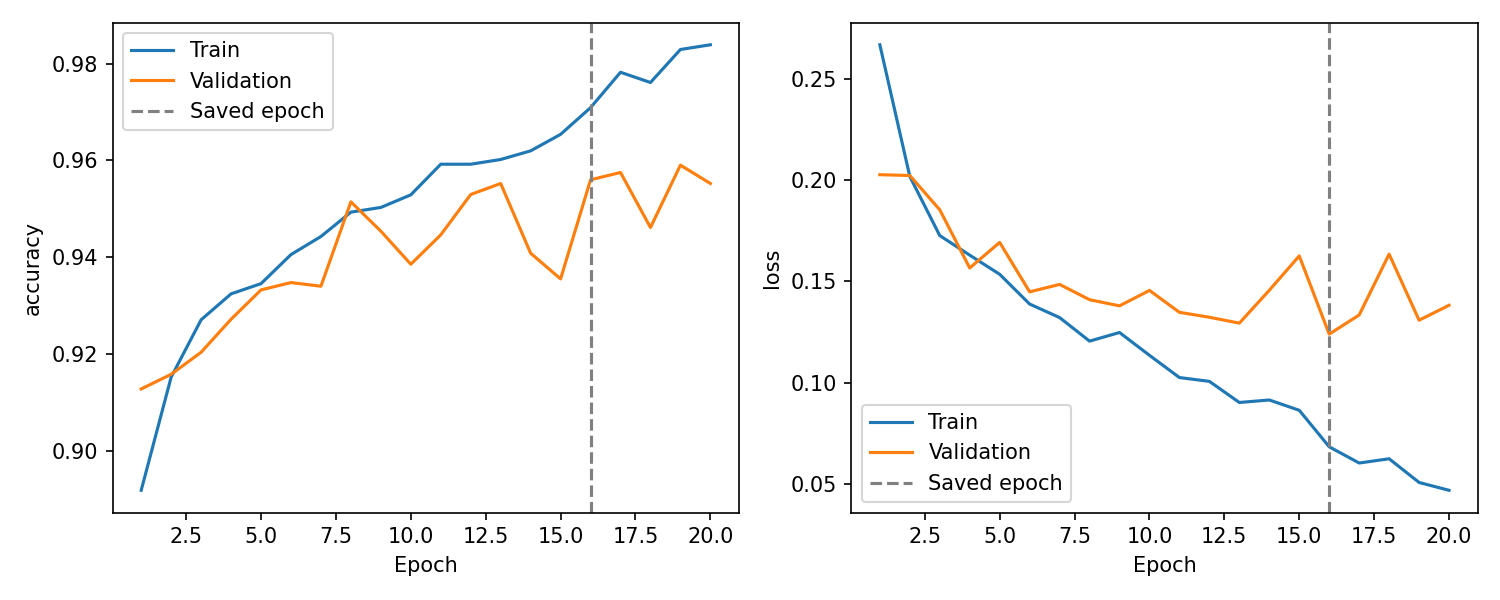

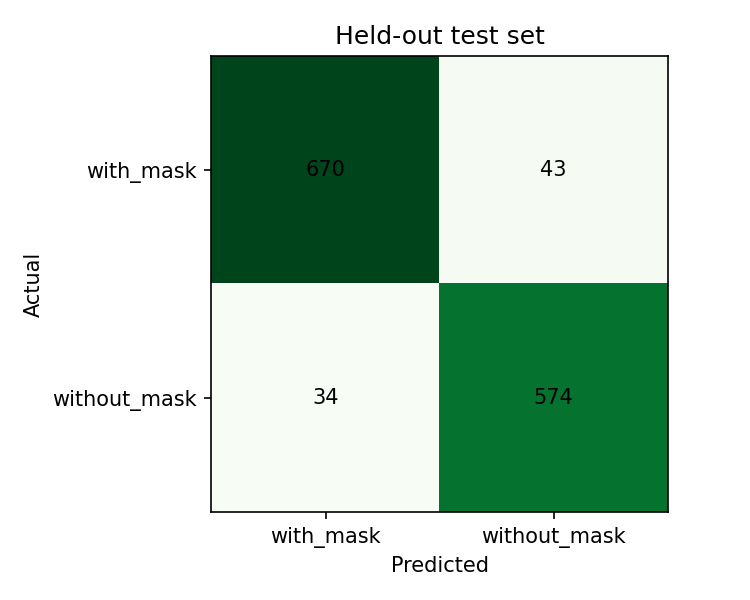

In [ ]:
evaluation = json.loads((RUN / 'reports/evaluation.json').read_text())
print(json.dumps(evaluation, indent=2))
from IPython.display import display, Image as DisplayImage
display(DisplayImage(filename=str(RUN / 'reports/training.png')))
display(DisplayImage(filename=str(RUN / 'reports/confusion_matrix.png')))


## 8. טעינה מחדש ותחזית לתמונה בודדת
ב־Colab תיפתח בחירת קובץ. בחרו תמונת פנים אחת בפורמט JPEG/PNG/WebP. בריצה מקומית נשתמש בדוגמת מבחן שנבחרה מראש, בלי לבחור לפי הצלחת המודל.

כאשר `p >= 0.5` נחזיר **ללא מסכה**, אחרת **עם מסכה**. זהו מסווג של תמונה שלמה, ולא גלאי פנים או גלאי מספר אנשים. הוא תמיד בוחר אחת משתי התוויות, גם אם העלינו חפץ אחר.

In [6]:
# שחזור אחרי ניתוק: הריצו תא זה ותאי ההגדרות 3–4 בלבד, ללא אימון
from pathlib import Path
import json, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
RUN = globals().get('RUN', Path('/content/drive/MyDrive/Project03_VISION') if IN_COLAB else Path.cwd())
PREPARED = globals().get('PREPARED', Path('/content/vision03_data/prepared') if IN_COLAB else RUN / 'data/prepared')
print('Saved artifacts:', RUN)
for folder in ['models', 'reports']:
    for path in sorted((RUN / folder).glob('*')):
        if path.is_file(): print(path.relative_to(RUN), path.stat().st_size)
print('Available test samples:', [str(p) for p in (PREPARED / 'test_samples').glob('*')])
print((RUN / 'models/metadata.json').read_text())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved artifacts: /content/drive/MyDrive/Project03_VISION
models/mask_cnn.keras 9803073
models/metadata.json 1292
reports/confusion_matrix.png 22210
reports/dataset_manifest.json 2677435
reports/evaluation.json 886
reports/history.csv 2106
reports/history.json 2587
reports/training.png 90317
Available test samples: []
{
  "version": "20261017T175219Z",
  "trained": true,
  "sha256": "14e1221d9bb28a8ece1278c3200e007f4ccde6650d642c65570a9c16bb785d79",
  "class_mapping": {
    "with_mask": 0,
    "without_mask": 1
  },
  "preprocessing": {
    "image_size": [
      64,
      64
    ],
    "channels": "RGB",
    "exif_transpose": true,
    "resize": "Pillow.BILINEAR",
    "dtype": "float32",
    "normalization": "divide_by_255",
    "input_shape": [
      null,
      64,
      64,
      3
    ],
    "sigmoid_positive_class": "without_mask",
    "threshold": 0.5
  

Saving with_mask.jpg to with_mask.jpg
{
  "file": "with_mask.jpg",
  "label": "with_mask",
  "probability_without_mask": 0.002060162601992488,
  "probability_with_mask": 0.9979398373980075,
  "model_version": "20261017T175219Z",
  "image_sha256": "83cdeb38911b00fd6959d84f60a56197a7037d496c96fa77812abcd8d8631e30",
  "preprocessed_sha256": "b1f027581b26a0a8258a552604b3e781bd7e1eb76e9532af69d9896374eaef0b"
}


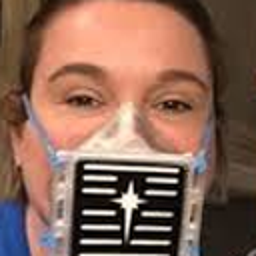

In [7]:
# אפשר להריץ שוב רק תא זה אחרי ביטול בחירת קובץ. אין אימון כאן.
from IPython.display import display
import sys, hashlib, json
IN_COLAB = 'google.colab' in sys.modules
saved_model, saved_metadata = load_bundle(RUN / 'models')
if IN_COLAB:
    from google.colab import files
    uploaded = files.upload()
else:
    uploaded = {'with_mask.jpg': (PREPARED / 'test_samples/with_mask.jpg').read_bytes()}
if not uploaded:
    print('הבחירה בוטלה. לחצו על ▶ בתא הזה כדי לבחור שוב; אין צורך באימון מחדש.')
elif len(uploaded) != 1:
    print('יש לבחור תמונה אחת בלבד. הריצו שוב רק תא זה.')
else:
    filename, image_bytes = next(iter(uploaded.items()))
    image_tensor = preprocess(image_bytes)
    probability = float(saved_model(image_tensor, training=False).numpy()[0, 0])
    result = {'file': filename, 'label': 'without_mask' if probability >= 0.5 else 'with_mask',
              'probability_without_mask': probability, 'probability_with_mask': 1-probability,
              'model_version': saved_metadata['version'],
              'image_sha256': hashlib.sha256(image_bytes).hexdigest(),
              'preprocessed_sha256': hashlib.sha256(image_tensor.tobytes()).hexdigest()}
    write_json(RUN / 'reports/single_image_prediction.json', result)
    print(json.dumps(result, indent=2, ensure_ascii=False))
    display(decode_image(image_bytes).resize((256, 256)))

## 9. הורדת הקבצים וחיבור לאתר
התא ייצור `vision03-model-artifacts.zip`. ב־Colab ההורדה תתחיל אוטומטית, ובנוסף העותק נשמר ב־Drive.

1. חלצו את ה־ZIP. העתיקו את **שני** הקבצים `models/mask_cnn.keras` ו־`models/metadata.json` לתיקיית `models` בפרויקט האתר.
2. העתיקו את קובצי `reports` לתיקיית `reports` באתר; עדכנו את המספרים ב־README לתוצאות הריצה שלכם.
3. הפעילו מחדש את FastAPI — המודל נטען רק בהפעלה.
4. העלו תמונה באתר, שמרו אותה בנפרד באמצעות ״שמור תמונה״, ולחצו ״בצע סיווג״.
5. ב־Colab בחרו **File → Download → Download .ipynb** ושמרו את המחברת עם הפלטים בתיקיית `notebooks`.
6. העלו ל־GitHub קוד, מחברת, README, קובץ מודל והגדרות. אין צורך להעלות את המאגר, `.venv` או `node_modules`.

**מגבלות להצגה:** אין זיהוי אדם/פנים, אין טיפול מובטח במסכה לא תקינה, ייתכנו תוויות רועשות ותמונות דומות. ההסתברות אינה מדד רפואי או הוכחה לנכונות. Unknown, ngrok ופריסה ציבורית הם בונוסים שאינם נדרשים כאן.

In [8]:
bundle = RUN / 'vision03-model-artifacts.zip'
with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED) as archive:
    for folder in ['models', 'reports']:
        for path in sorted((RUN / folder).glob('*')):
            if path.is_file(): archive.write(path, path.relative_to(RUN))
print('Download:', bundle)
if IN_COLAB:
    from google.colab import files
    files.download(str(bundle))


Download: /content/drive/MyDrive/Project03_VISION/vision03-model-artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>